# Ⅰ第3回 演習2 過学習を作る

**問い**：訓練データを 1,000 枚に減らして長く学習すると，検証の成績はどうなるか．

教科書 第5章のテーマ「過学習」を，自分の手で起こす．題材は第1回 GW3 試行①（FashionMNIST × MLP）で，コードは教科書のコードテンプレート①〜⑪の形のまま．
違うのは **訓練 1,000 枚（元は 48,000 枚）・50 エポック（元は 20）** だけ．実行は 20〜40 秒．

## (0) グループと番号の設定

In [1]:
# ===== (0) グループと番号の設定 =====
GROUP_ID = 6                  # ← 自分のグループ番号 (1〜27) に書き換える
MEMBER_NO = 3                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/niirowakana/AI_TD


## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 検証損失が一番小さくなるのは何エポック目か：5
- 50 エポック後の正解率：訓練 80％，検証 80％

## (1) コードテンプレート①⑤：ライブラリのインポートと使用デバイス

In [2]:
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
import matplotlib.pyplot as plt
import seaborn as sns
from common.device import get_device, synchronize
from common.logger import ResultLogger
from common.todo import todo_check, checkpoint
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

# コードテンプレート⑤：使用デバイスの選択（get_device は⑤にメモリ上限を加えたもの）
device = get_device()
print("使用デバイス:", device)

使用デバイス: mps


## (2) コードテンプレート②③④：データ（訓練 1,000 枚・検証 12,000 枚）

In [3]:
N_TRAIN = 1000      # (8) で 3000 に変えてもう一度実行する

# コードテンプレート②：データ前処理（画像をテンソルに変換する）
data_transform = transforms.Compose([
    transforms.ToTensor(),
])

# コードテンプレート③：乱数の種を固定し，FashionMNIST の訓練用データを 8:2 に分ける（GW3 試行①と同じ）
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(0)
train_val_dataset = datasets.FashionMNIST(root=str(ROOT / "assets" / "data"), train=True, download=True, transform=data_transform)
train_size = int(0.8 * len(train_val_dataset))
val_size = len(train_val_dataset) - train_size
train_dataset, val_dataset = random_split(train_val_dataset, [train_size, val_size])
train_dataset = Subset(train_dataset, range(N_TRAIN))     # 授業で追加：訓練データを先頭の N_TRAIN 枚だけ使う

# コードテンプレート④：データローダの作成
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"訓練データ数: {len(train_dataset)} 枚 | 検証データ数: {len(val_dataset)} 枚")

訓練データ数: 1000 枚 | 検証データ数: 12000 枚


## (3) コードテンプレート⑦⑧⑨：モデル・損失関数・最適化手法（GW3 試行①と同じ）

In [4]:
# コードテンプレート⑦：ネットワークの定義
INPUT_SIZE = 1 * 28 * 28    # チャネル × 高さ × 幅
HIDDEN_SIZE1 = 512
HIDDEN_SIZE2 = 256
OUTPUT_SIZE = 10
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(INPUT_SIZE, HIDDEN_SIZE1),
    nn.ReLU(),
    nn.Linear(HIDDEN_SIZE1, HIDDEN_SIZE2),
    nn.ReLU(),
    nn.Linear(HIDDEN_SIZE2, OUTPUT_SIZE)
)
model.to(device)

# コードテンプレート⑧：損失関数
criterion = nn.CrossEntropyLoss()
# コードテンプレート⑨：最適化手法
optimizer = optim.Adam(model.parameters(), lr=0.001)

## (4) コードテンプレート⑩：学習（エポックごとに訓練と検証の損失・正解率を記録する）

In [5]:
EPOCHS = 50
# エポックごとの損失と正解率を記録するリスト
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

synchronize(device)
t0 = time.perf_counter()
for epoch in range(EPOCHS):
    # 訓練モードにする
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    train_loss_list.append(train_loss / train_total)
    train_acc_list.append(100.0 * train_correct / train_total)

    # 評価モードにする：検証データで確かめる（重みは更新しない）
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_loss_list.append(val_loss / val_total)
    val_acc_list.append(100.0 * val_correct / val_total)

    if (epoch + 1) % 5 == 0:     # 授業では 5 エポックごとに表示する
        print(f"Epoch {epoch + 1}/{EPOCHS}, Train Loss: {train_loss_list[-1]:.4f}, Train Acc: {train_acc_list[-1]:.2f}%, "
              f"Val Loss: {val_loss_list[-1]:.4f}, Val Acc: {val_acc_list[-1]:.2f}%")
synchronize(device)
train_sec = time.perf_counter() - t0
print(f"学習時間 {train_sec:.1f} 秒")

Epoch 5/50, Train Loss: 0.5720, Train Acc: 79.60%, Val Loss: 0.6752, Val Acc: 75.12%
Epoch 10/50, Train Loss: 0.3570, Train Acc: 86.80%, Val Loss: 0.5920, Val Acc: 78.96%
Epoch 15/50, Train Loss: 0.2793, Train Acc: 89.50%, Val Loss: 0.6532, Val Acc: 77.87%
Epoch 20/50, Train Loss: 0.1724, Train Acc: 94.40%, Val Loss: 0.6031, Val Acc: 81.05%
Epoch 25/50, Train Loss: 0.1067, Train Acc: 96.50%, Val Loss: 0.6990, Val Acc: 80.59%
Epoch 30/50, Train Loss: 0.0798, Train Acc: 98.00%, Val Loss: 0.7401, Val Acc: 81.20%
Epoch 35/50, Train Loss: 0.0444, Train Acc: 99.20%, Val Loss: 0.8214, Val Acc: 80.55%
Epoch 40/50, Train Loss: 0.0549, Train Acc: 98.70%, Val Loss: 0.8825, Val Acc: 79.75%
Epoch 45/50, Train Loss: 0.0163, Train Acc: 99.90%, Val Loss: 0.9312, Val Acc: 81.02%
Epoch 50/50, Train Loss: 0.0099, Train Acc: 100.00%, Val Loss: 0.9906, Val Acc: 80.90%
学習時間 53.4 秒


## (5) コードテンプレート⑪：学習曲線

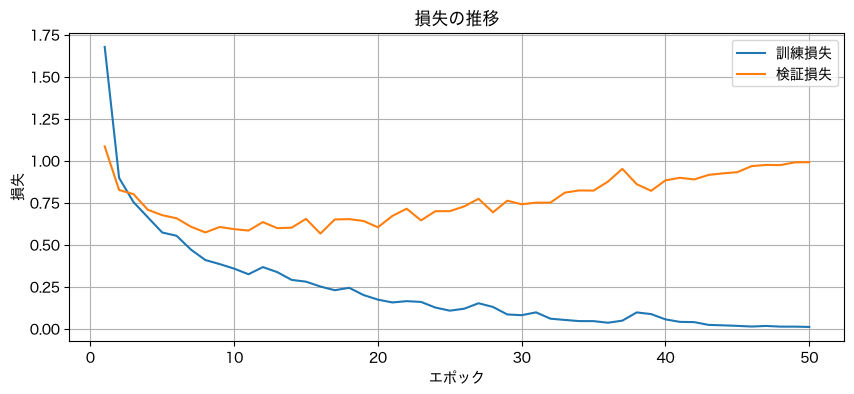

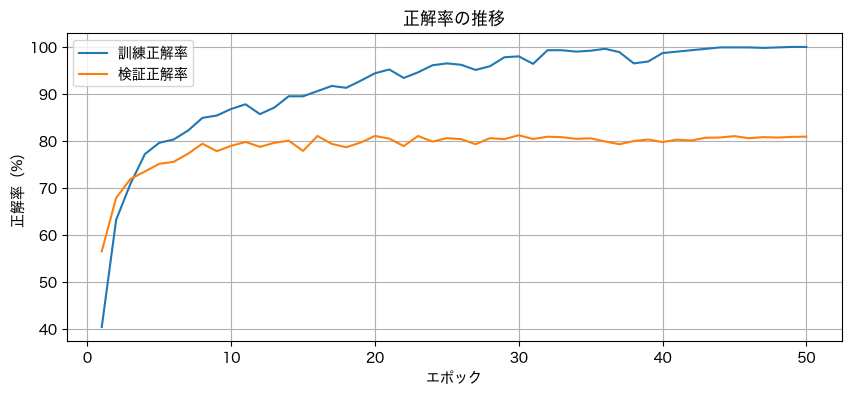

In [6]:
# コードテンプレート⑪：学習結果の可視化（訓練と検証を比べる）
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 4))
sns.lineplot(x=epochs, y=train_loss_list, label="訓練損失")
sns.lineplot(x=epochs, y=val_loss_list, label="検証損失")
plt.title("損失の推移"); plt.xlabel("エポック"); plt.ylabel("損失"); plt.legend(); plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
sns.lineplot(x=epochs, y=train_acc_list, label="訓練正解率")
sns.lineplot(x=epochs, y=val_acc_list, label="検証正解率")
plt.title("正解率の推移"); plt.xlabel("エポック"); plt.ylabel("正解率（%）"); plt.legend(); plt.grid(True)
plt.show()

## (6) 数字で読む

- **最良エポック**：検証損失が一番小さいエポック
- **汎化ギャップ**：訓練正解率 − 検証正解率（％の差＝ポイント．大きいほど，訓練データに合わせすぎている）

In [8]:
# TODO 1: 「...」を消して，検証損失が一番小さいエポックの番号（1 から数える）を求める
#   ヒント：リストの最小値は min(リスト)，その位置は リスト.index(値)
best_epoch = val_loss_list.index(min(val_loss_list)) + 1
# TODO 2: 「...」を消して，50 エポック後の汎化ギャップ（訓練正解率 − 検証正解率）を求める．最後の要素は リスト[-1]
gap = train_acc_list[-1] - val_acc_list[-1]

todo_check("TODO 1・2")
print(f"最良エポック {best_epoch}：検証損失 {val_loss_list[best_epoch - 1]:.3f}，検証正解率 {val_acc_list[best_epoch - 1]:.1f}%")
print(f"50 エポック後：検証損失 {val_loss_list[-1]:.3f}，検証正解率 {val_acc_list[-1]:.1f}%")
print(f"汎化ギャップ {gap:.1f} ポイント")

最良エポック 16：検証損失 0.566，検証正解率 81.0%
50 エポック後：検証損失 0.991，検証正解率 80.9%
汎化ギャップ 19.1 ポイント


## ✋ 止まる 1：ここから先へは，グループ全員がそろってから進む

**問い**：過学習はいつ始まったか．グラフのどこを見るとそう言えるか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：コードの行と出力を指して根拠を言い，自分の数値がほかの人と同じか確かめる．根拠になる所：(5) の損失のグラフで，訓練損失と検証損失が離れはじめるところ．(6) の最良エポック
3. 全員が下のセルの `CP1 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [9]:
# 問い：過学習はいつ始まったか．グラフのどこを見るとそう言えるか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP1 = "過学習は8エポックごろから始まった。(5)の損失のグラフで、訓練損失は50エポックまで下がり続けたのに、検証損失は8エポック目の0.574が一番小さく、そのあと上がりはじめて訓練損失と離れていったから。"
checkpoint(CP1, "止まる 1")

止まる 1 OK：過学習は8エポックごろから始まった。(5)の損失のグラフで、訓練損失は50エポックまで下がり続けたのに、検証損失は8エポック目の0.574が一番小さく、そのあと上がりはじめて訓練損失と離れていったから。


## (7) 記録

In [10]:
metrics = {"best_epoch": best_epoch, "best_val_loss": val_loss_list[best_epoch - 1],      # 正解率は 0〜1 で記録する
           "best_val_acc": val_acc_list[best_epoch - 1] / 100, "final_val_loss": val_loss_list[-1],
           "final_val_acc": val_acc_list[-1] / 100, "final_train_acc": train_acc_list[-1] / 100,
           "gap": gap / 100, "train_sec": train_sec}
metrics.update({f"val_loss_ep{i + 1:02d}": v for i, v in enumerate(val_loss_list)})
logger = ResultLogger(GROUP_ID, f"member{MEMBER_NO}", course="c1", day="d3", exercise="ex2", device=device)
logger.log_many(metrics, condition=f"n{N_TRAIN}", seed=0)
print("書き込み先:", logger.path)

書き込み先: /Users/niirowakana/AI_TD/results/c1_d3_ex2_06.csv


## (8) 全員：訓練データを増やすとどうなるか

先に (6) の出力（最良エポック・汎化ギャップ）を下の ✋ 2 のセルの上などにメモしておく．それから (2) の `N_TRAIN` を 3000 にして，(2) から (7) までをもう一度実行する（1 分ほど）．CSV には 1,000 枚と 3,000 枚の両方が残る．最良エポックと汎化ギャップが 1,000 枚のときとどう違うかを確かめる．

## ✋ 止まる 2：ここから先へは，グループ全員がそろってから進む

**問い**：訓練データを 3,000 枚に増やすと，最良エポックと汎化ギャップはどう変わったか

1. **presenter**（この演習の担当）：問いを読み上げ，話し合いを進める．全員の考えを聞き，根拠を含めて答えを 1〜2 文にまとめる
2. **全員**：コードの行と出力を指して根拠を言い，自分の数値がほかの人と同じか確かめる．根拠になる所：1,000 枚のときと 3,000 枚のときの (6) の出力
3. 全員が下のセルの `CP2 = ""` に答えを書いて実行する（10 文字未満だと止まる）

In [11]:
# 問い：訓練データを 3,000 枚に増やすと，最良エポックと汎化ギャップはどう変わったか
# ▼ グループで決めた答えを " " の中に書く（1〜2 文）
CP2 = "訓練データを3,000枚に増やすと、最良エポックは8から12に遅くなり、汎化ギャップは19.2から15.3ポイントに小さくなった。データが多いと訓練データを丸暗記しにくくなり、過学習が始まるのが遅く、程度も小さくなった。"
checkpoint(CP2, "止まる 2")

止まる 2 OK：訓練データを3,000枚に増やすと、最良エポックは8から12に遅くなり、汎化ギャップは19.2から15.3ポイントに小さくなった。データが多いと訓練データを丸暗記しにくくなり、過学習が始まるのが遅く、程度も小さくなった。


## (9) 考察（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 予測と比べて，当たったこと・外れたこと：50エポック後の検証正解率は80%と予測して80.7%で当たり，最良エポックも5と予測して8で近かった．一番外れたのは訓練正解率で，検証と同じ80%くらいになると予測したが，実際は99.9%まで上がった．1,000枚しかない訓練データを何度もくり返し学習すると，モデルが訓練データを丸暗記してしまい，訓練と検証の差（汎化ギャップ19.2ポイント）がこんなに大きく開くとは思っていなかった．
2. 最良エポックのあとも学習を続けると，訓練損失と検証損失はそれぞれどうなったか．それはなぜか：1,000枚では，訓練損失は 0.57 から 0.013 まで下がり続けたが，検証損失は8エポック目の 0.574 を最小にして，50エポック後には 0.999 まで上がった．モデルが訓練データの細かい特徴や偶然のばらつきまで覚えてしまい，訓練データには合うが，初めて見る検証データには合わなくなった（過学習）からだ．
3. 50 エポック後のモデルと最良エポックのモデルのどちらを使うべきか．数値を使って理由を書く：最良エポックのモデルを使うべきだ．検証正解率は 50エポック後が 80.7%，最良エポックが 79.3% とほぼ同じだが，検証損失は 0.999 と 0.574 で 50エポック後のほうがずっと悪い．50エポック後のモデルは，間違えるときも自信満々に間違えるようになっていて，汎化ギャップも 19.2 ポイントと大きいので，未知のデータでは信頼しにくい．